In [12]:
import matplotlib.pyplot as plt
import pandas as pd
import pylab as pl
import numpy as np
%matplotlib inline

In [65]:
df = pd.read_csv("FuelConsumption.csv")

# take a look at the dataset
df.head()



,MODELYEAR,MAKE,MODEL,VEHICLECLASS,ENGINESIZE,CYLINDERS,TRANSMISSION,FUELTYPE,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,FUELCONSUMPTION_COMB_MPG,CO2EMISSIONS
0,2014,ACURA,ILX,COMPACT,2.0,4,AS5,Z,9.9,6.7,8.5,33,196
1,2014,ACURA,ILX,COMPACT,2.4,4,M6,Z,11.2,7.7,9.6,29,221
2,2014,ACURA,ILX HYBRID,COMPACT,1.5,4,AV7,Z,6.0,5.8,5.9,48,136
3,2014,ACURA,MDX 4WD,SUV - SMALL,3.5,6,AS6,Z,12.7,9.1,11.1,25,255
4,2014,ACURA,RDX AWD,SUV - SMALL,3.5,6,AS6,Z,12.1,8.7,10.6,27,244


In [14]:
# summarize the data
df.describe()

,MODELYEAR,ENGINESIZE,CYLINDERS,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,FUELCONSUMPTION_COMB_MPG,CO2EMISSIONS
count,1067.0,1067.000000,1067.000000,1067.000000,1067.000000,1067.000000,1067.000000,1067.000000
mean,2014.0,3.346298,5.794752,13.296532,9.474602,11.580881,26.441425,256.228679
std,0.0,1.415895,1.797447,4.101253,2.794510,3.485595,7.468702,63.372304
min,2014.0,1.000000,3.000000,4.600000,4.900000,4.700000,11.000000,108.000000
25%,2014.0,2.000000,4.000000,10.250000,7.500000,9.000000,21.000000,207.000000
50%,2014.0,3.400000,6.000000,12.600000,8.800000,10.900000,26.000000,251.000000
75%,2014.0,4.300000,8.000000,15.550000,10.850000,13.350000,31.000000,294.000000
max,2014.0,8.400000,12.000000,30.200000,20.500000,25.800000,60.000000,488.000000


In [15]:
import numpy as np
import matplotlib.pyplot as plt

def plot_scatter_simple(x, y, xlabel="X", ylabel="Y", title=None,
                        color="#2E86AB", alpha=0.6, figsize=(10, 6)):
    fig, ax = plt.subplots(figsize=figsize, dpi=110)
    x_arr, y_arr = np.asarray(x), np.asarray(y)

    ax.scatter(x_arr, y_arr, color=color, alpha=alpha, s=70,
               edgecolor='white', linewidth=1.2, zorder=3)

    # خط رگرسیون با numpy (بدون scipy)
    slope, intercept = np.polyfit(x_arr, y_arr, 1)
    line_x = np.linspace(x_arr.min(), x_arr.max(), 100)
    ax.plot(line_x, slope * line_x + intercept,
            color='#E63946', linewidth=2.5, zorder=4,
            label=f'y = {slope:.2f}x + {intercept:.2f}')

    # R² با numpy
    y_pred = slope * x_arr + intercept
    ss_res = np.sum((y_arr - y_pred) ** 2)
    ss_tot = np.sum((y_arr - y_arr.mean()) ** 2)
    r2 = 1 - ss_res / ss_tot
    ax.text(0.03, 0.97, f'$R^2$ = {r2:.3f}', transform=ax.transAxes,
            fontsize=11, va='top',
            bbox=dict(boxstyle='round,pad=0.6', facecolor='white',
                      edgecolor='#ccc', alpha=0.9))

    ax.set_xlabel(xlabel, fontsize=13, fontweight='bold')
    ax.set_ylabel(ylabel, fontsize=13, fontweight='bold')
    ax.set_title(title or f'{ylabel} vs {xlabel}',
                 fontsize=15, fontweight='bold', pad=15)
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend(loc='lower right', fontsize=10)
    ax.spines[['top', 'right']].set_visible(False)

    plt.tight_layout()
    plt.show()
    return ax


import numpy as np
import matplotlib.pyplot as plt

def plot_scatter_poly(x, y, xlabel="X", ylabel="Y", title=None,
                      color="#2E86AB", alpha=0.6, figsize=(10, 6),
                      degree=2):
    """
    نمودار پراکندگی با منحنی رگرسیون چندجمله‌ای (غیرخطی)
    
    degree : int — درجه منحنی (۲ = سهمی، ۳ = مکعبی، ...)
    """
    fig, ax = plt.subplots(figsize=figsize, dpi=110)
    x_arr, y_arr = np.asarray(x), np.asarray(y)

    # نقاط
    ax.scatter(x_arr, y_arr, color=color, alpha=alpha, s=70,
               edgecolor='white', linewidth=1.2, zorder=3,
               label='Data points')

    # برازش چندجمله‌ای (غیرخطی)
    coeffs = np.polyfit(x_arr, y_arr, degree)
    poly = np.poly1d(coeffs)

    # منحنی
    line_x = np.linspace(x_arr.min(), x_arr.max(), 300)
    line_y = poly(line_x)
    ax.plot(line_x, line_y, color='#E63946', linewidth=2.5, zorder=4,
            label=f'Polynomial fit (degree={degree})')

    # R² برای برازش چندجمله‌ای
    y_pred = poly(x_arr)
    ss_res = np.sum((y_arr - y_pred) ** 2)
    ss_tot = np.sum((y_arr - y_arr.mean()) ** 2)
    r2 = 1 - ss_res / ss_tot

    # ساخت متن معادله
    terms = []
    for i, c in enumerate(coeffs):
        power = degree - i
        if power == 0:
            terms.append(f"{c:+.2f}")
        elif power == 1:
            terms.append(f"{c:+.2f}x")
        else:
            terms.append(f"{c:+.2f}x$^{power}$")
    eq_str = " ".join(terms)

    # باکس آماره
    stats_text = f'$R^2$ = {r2:.3f}\n{eq_str}'
    ax.text(0.03, 0.97, stats_text, transform=ax.transAxes,
            fontsize=10, va='top',
            bbox=dict(boxstyle='round,pad=0.6', facecolor='white',
                      edgecolor='#ccc', alpha=0.9))

    # برچسب‌ها
    ax.set_xlabel(xlabel, fontsize=13, fontweight='bold')
    ax.set_ylabel(ylabel, fontsize=13, fontweight='bold')
    ax.set_title(title or f'{ylabel} vs {xlabel} (non-linear fit)',
                 fontsize=15, fontweight='bold', pad=15)
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend(loc='lower right', fontsize=10)
    ax.spines[['top', 'right']].set_visible(False)

    plt.tight_layout()
    plt.show()
    return ax

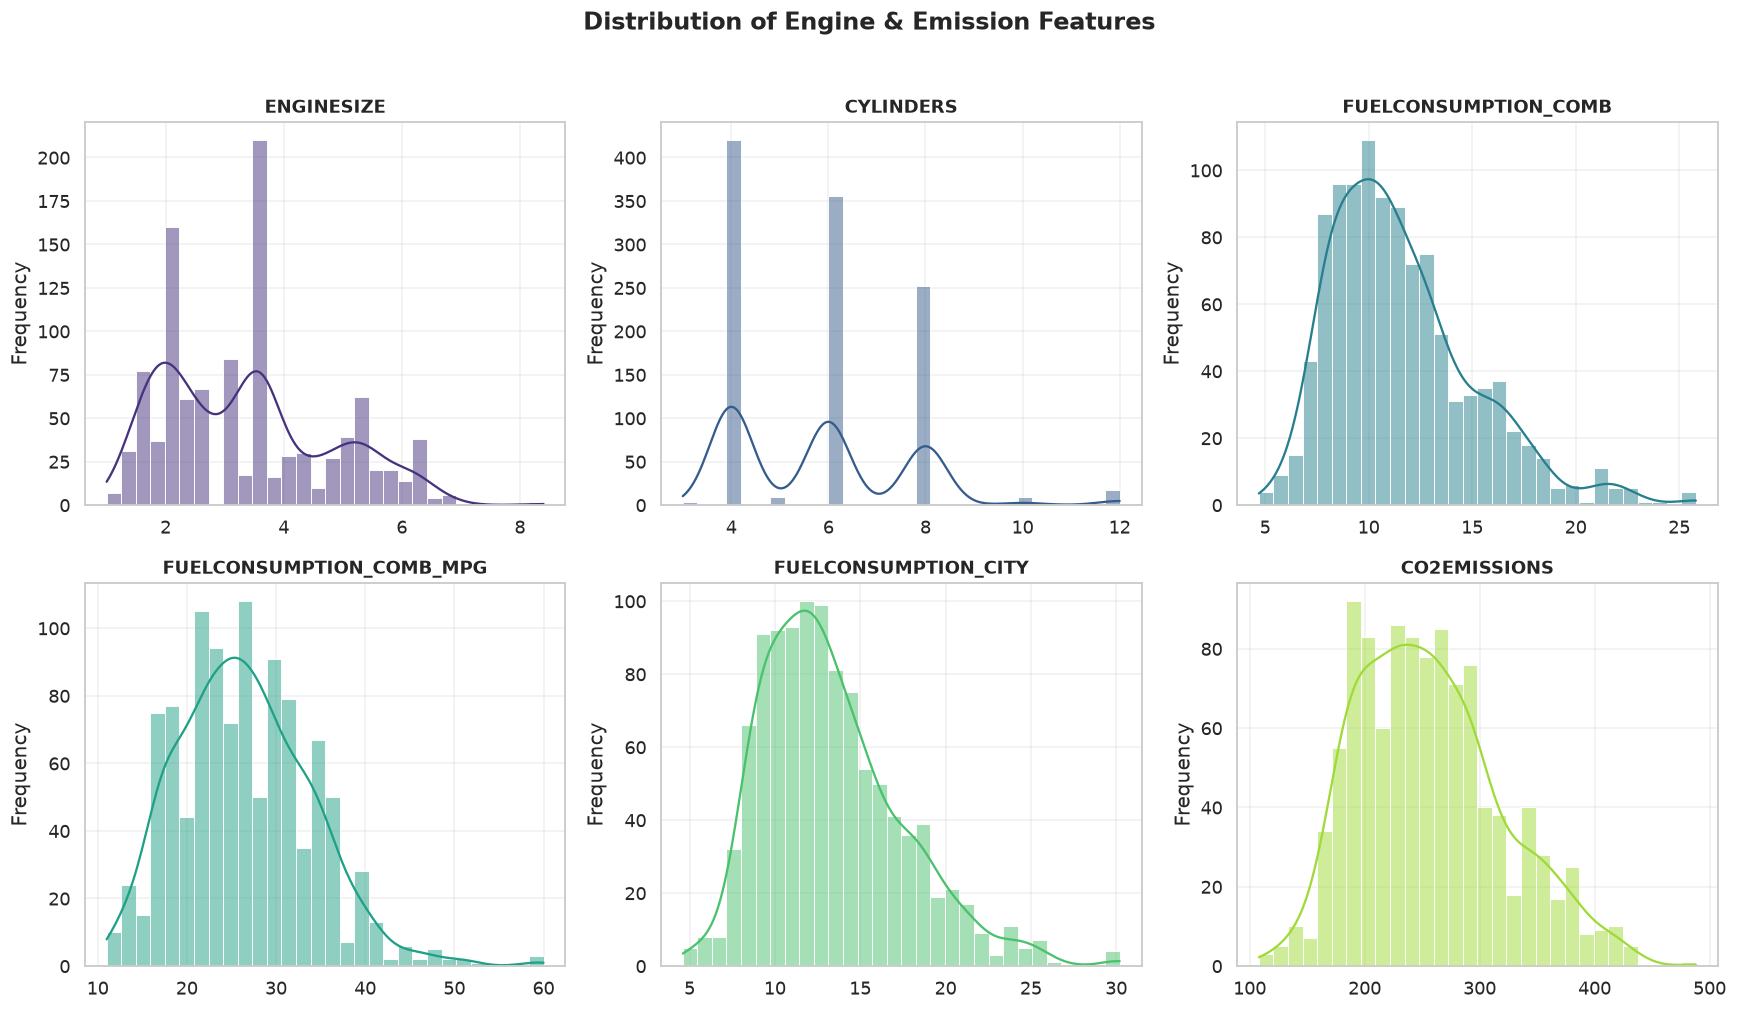

In [67]:
import matplotlib.pyplot as plt
import seaborn as sns

# --- 1) انتخاب ستون‌ها (بدون تکرار) ---
cols = ['ENGINESIZE', 'CYLINDERS', 'FUELCONSUMPTION_COMB',
        'FUELCONSUMPTION_COMB_MPG', 'FUELCONSUMPTION_CITY', 'CO2EMISSIONS']

viz = df[cols].copy()
cdf =  df[cols].copy()
# --- 2) تنظیم استایل کلی ---
sns.set_style("whitegrid")
sns.set_context("notebook", font_scale=1.1)
plt.rcParams['figure.dpi'] = 110

# --- 3) ساخت شبکه‌ی 2×3 هیستوگرام با KDE ---
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

colors = sns.color_palette("viridis", len(cols))

for i, col in enumerate(cols):
    sns.histplot(
        data=viz,
        x=col,
        bins=30,
        kde=True,
        color=colors[i],
        edgecolor='white',
        linewidth=0.6,
        ax=axes[i]
    )
    axes[i].set_title(col, fontsize=12, fontweight='bold')
    axes[i].set_xlabel('')      # محور x رو خالی می‌کنیم چون عنوان بالا هست
    axes[i].set_ylabel('Frequency')
    axes[i].grid(alpha=0.3)

# --- 4) تنظیم فاصله‌ها و یک عنوان کلی ---
fig.suptitle('Distribution of Engine & Emission Features',
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

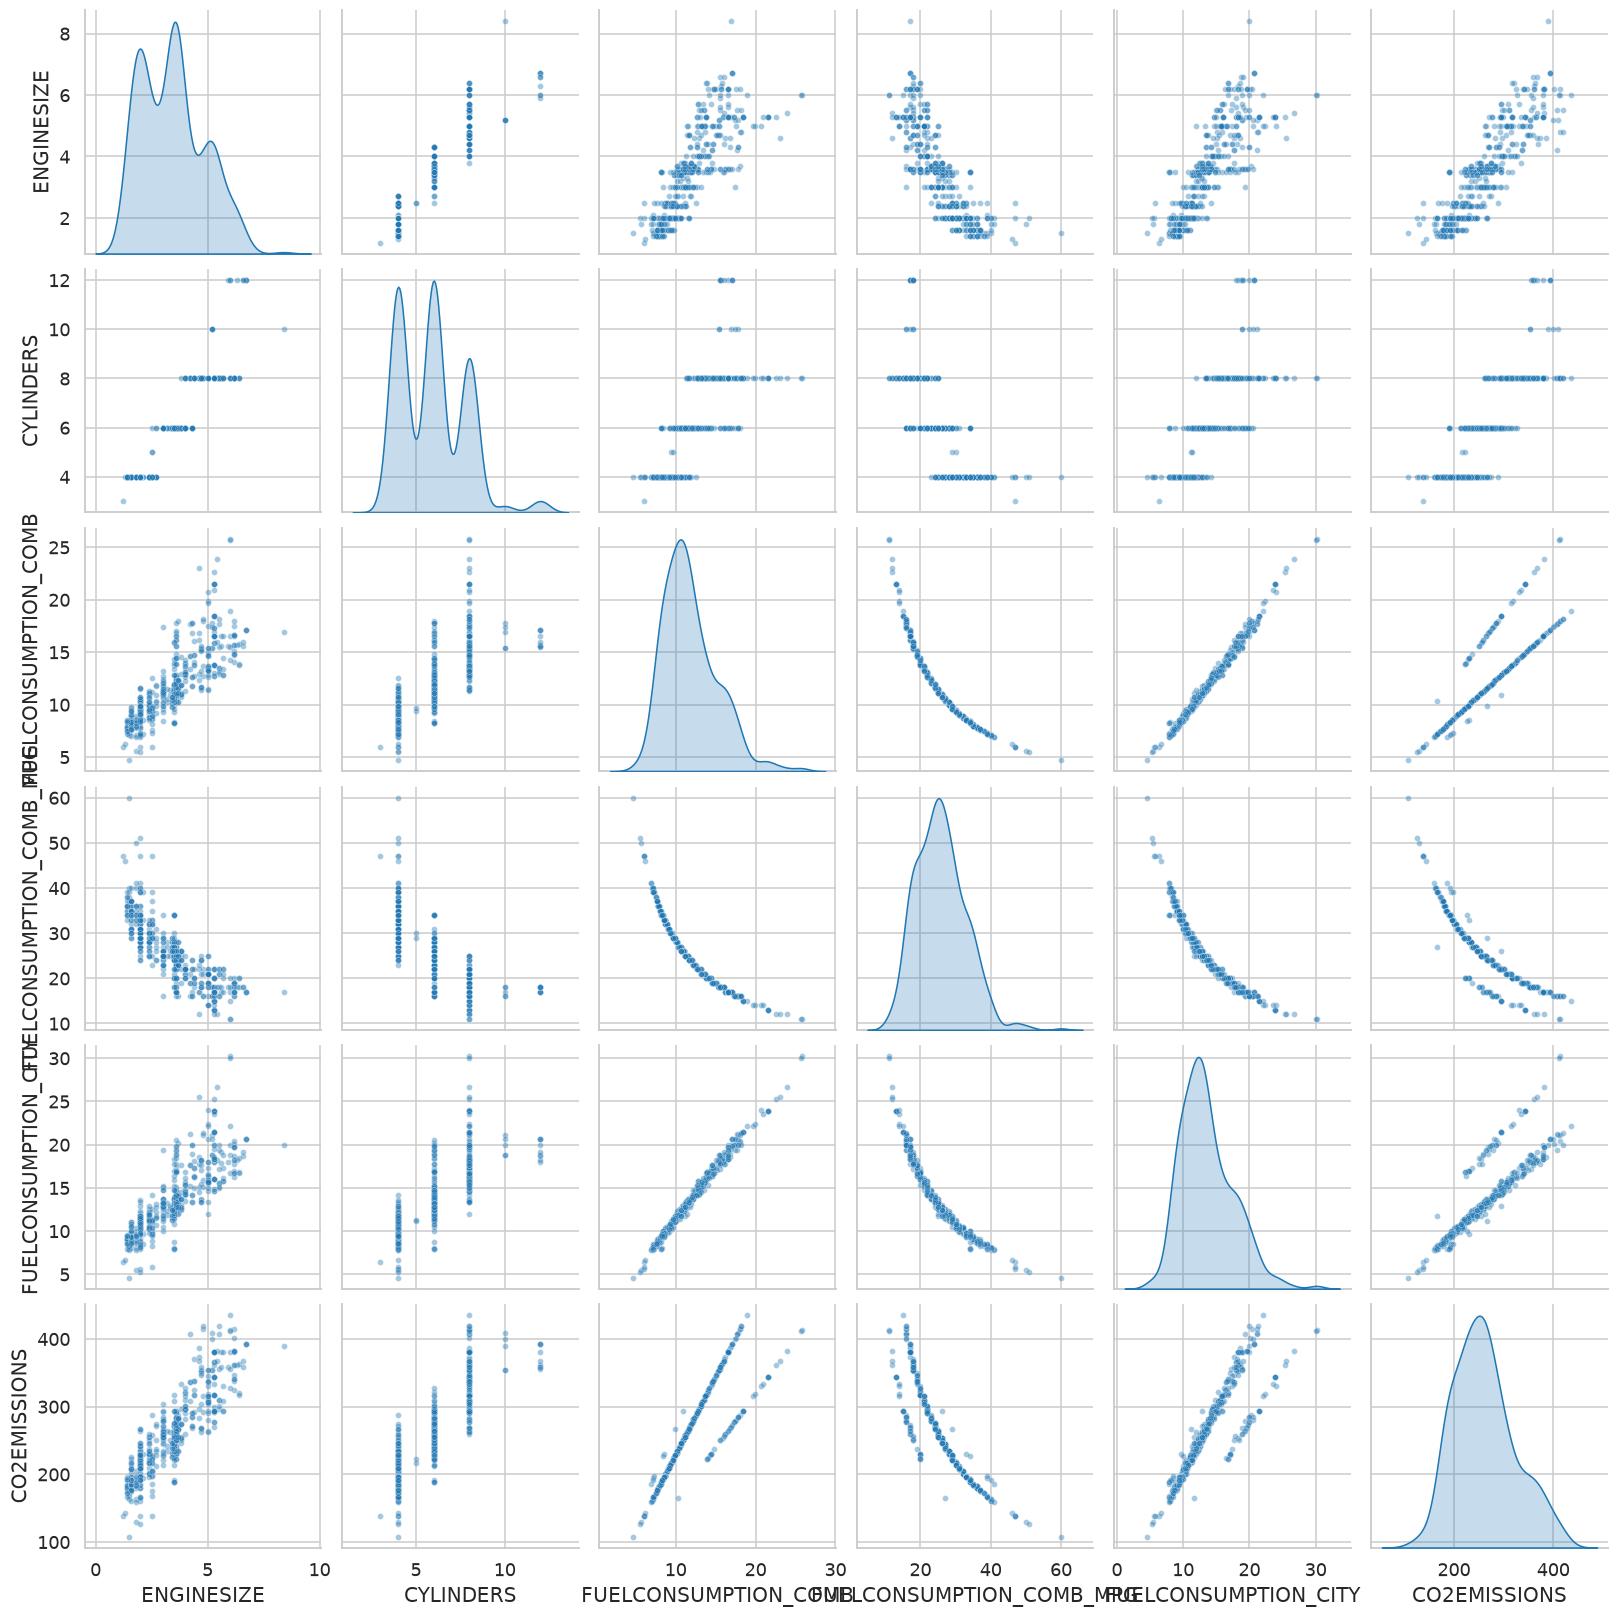

In [68]:
sns.pairplot(viz.sample(min(500, len(viz))), 
             diag_kind='kde', 
             plot_kws={'alpha':0.4, 's':15})
plt.show()

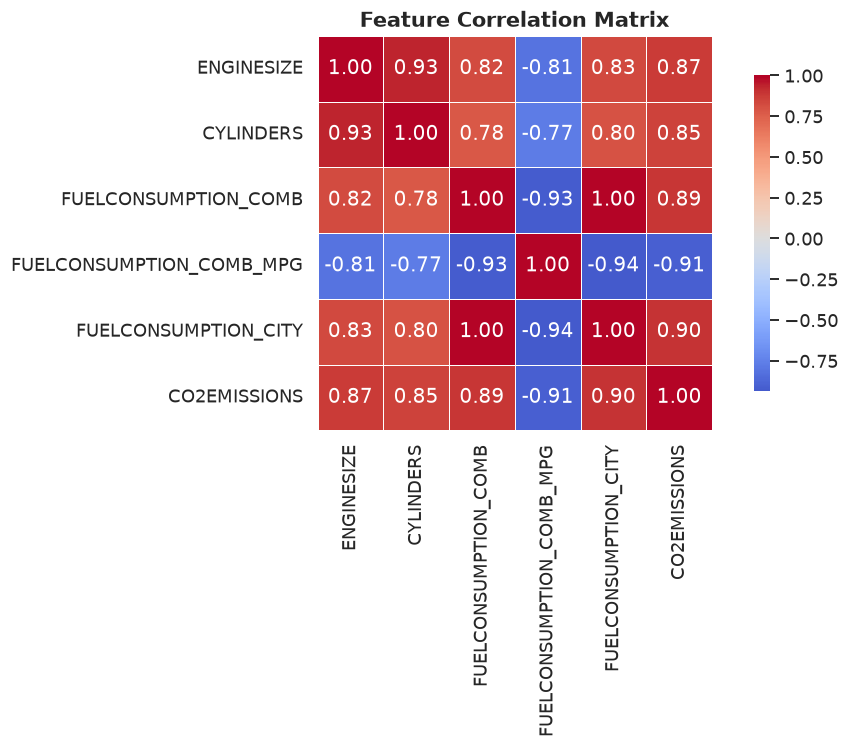

In [69]:
plt.figure(figsize=(10, 7))
sns.heatmap(viz.corr(), annot=True, fmt=".2f",
            cmap="coolwarm", center=0, square=True,
            linewidths=0.5, cbar_kws={"shrink": .8})
plt.title("Feature Correlation Matrix", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

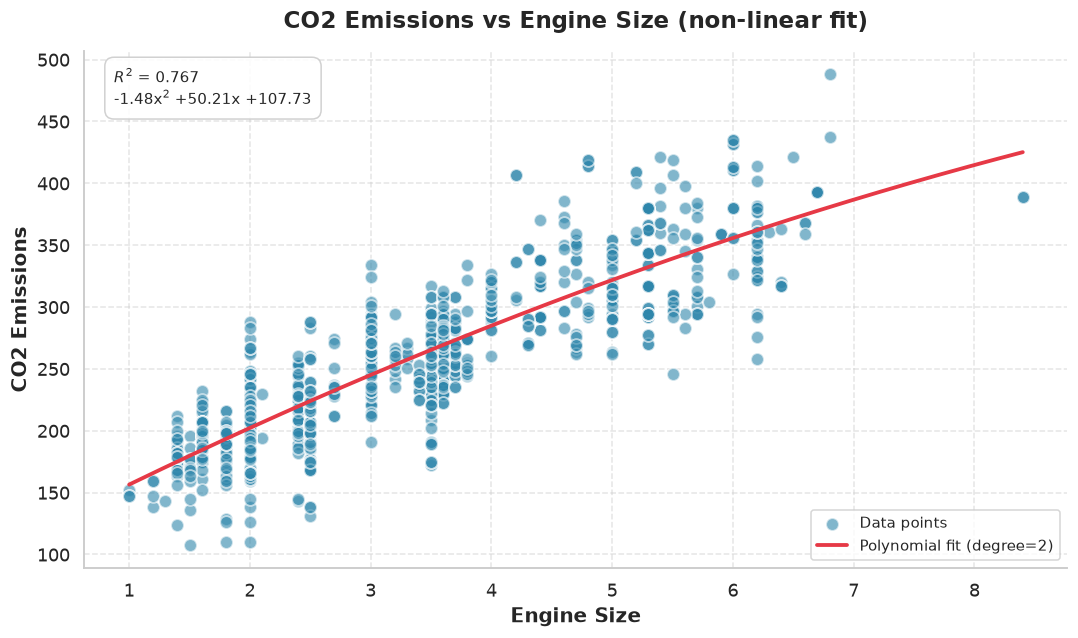

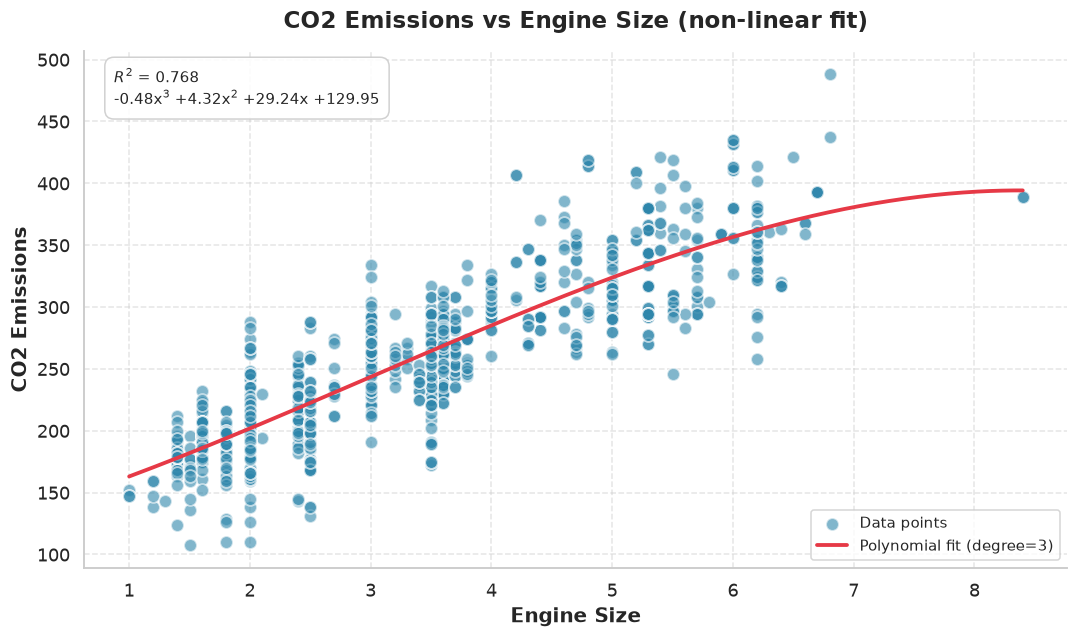

<Axes: title={'center': 'CO2 Emissions vs Engine Size (non-linear fit)'}, xlabel='Engine Size', ylabel='CO2 Emissions'>

In [70]:
# منحنی درجه ۲ (پیش‌فرض) — سهمی
plot_scatter_poly(cdf.ENGINESIZE, cdf.CO2EMISSIONS,
                  xlabel="Engine Size", ylabel="CO2 Emissions")

# منحنی درجه ۳ — مکعبی
plot_scatter_poly(cdf.ENGINESIZE, cdf.CO2EMISSIONS,
                  xlabel="Engine Size", ylabel="CO2 Emissions",
                  degree=3)

In [34]:
print(cdf.ENGINESIZE.to_numpy(), cdf.CO2EMISSIONS.to_numpy())

[2.  2.4 1.5 ... 3.  3.2 3.2] [196 221 136 ... 271 260 294]


In [49]:
from sklearn.model_selection import train_test_split

# Input feature
X = cdf[['ENGINESIZE']]
# Target
y = cdf['CO2EMISSIONS']

# Split data
x_train, x_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [50]:
from sklearn import linear_model
regr = linear_model.LinearRegression()
regr.fit (x_train, y_train)
# The coefficients
print ('Coefficients: ', regr.coef_)
print ('Intercept: ',regr.intercept_)



Coefficients:  [38.99297872]
Intercept:  126.28970217408721


In [54]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
y_pred = regr.predict(x_test)

print("Mean absolute error: %.2f" % np.mean(np.abs(y_pred - y_test)))
print("Mean squared error: %.2f" % np.mean((y_pred - y_test) ** 2))
print("R2-score: %.2f" % r2_score(y_test, y_pred))

Mean absolute error: 24.10
Mean squared error: 985.94
R2-score: 0.76


In [55]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import r2_score


# Polynomial regression, degree 2
model = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression()
)

# Train
model.fit(x_train, y_train)


# Predict
y_pred = model.predict(x_test)

print("Mean absolute error: %.2f" % np.mean(np.abs(y_pred - y_test)))
print("Mean squared error: %.2f" % np.mean((y_pred - y_test) ** 2))
# Evaluate
print("R2-score:", r2_score(y_test, y_pred))

Mean absolute error: 23.92
Mean squared error: 960.87
R2-score: 0.7676219471812654


In [72]:
# just engine size # we will add that some property 

cdf.columns
# CYLINDERS 
# FUELCONSUMPTION_COMB
# 

Index(['ENGINESIZE', 'CYLINDERS', 'FUELCONSUMPTION_COMB',
       'FUELCONSUMPTION_COMB_MPG', 'FUELCONSUMPTION_CITY', 'CO2EMISSIONS'],
      dtype='str')

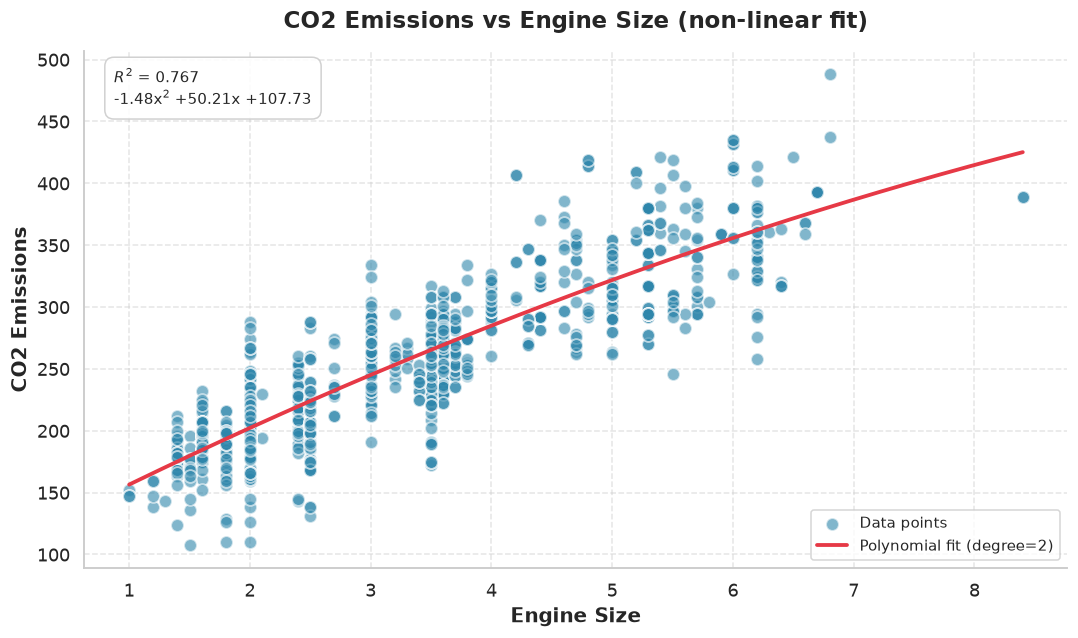

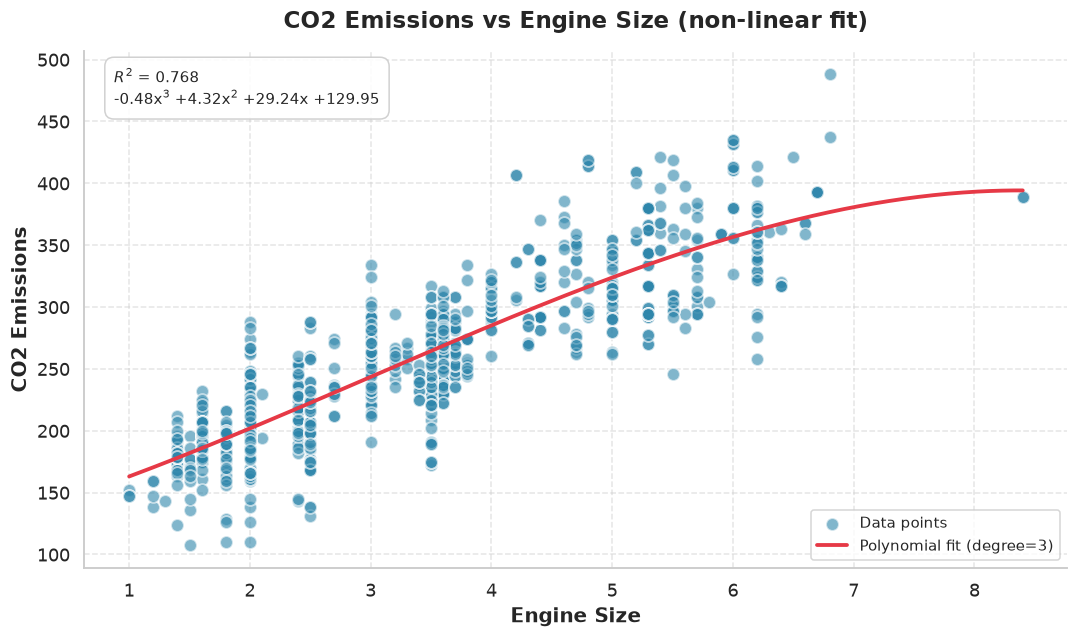

<Axes: title={'center': 'CO2 Emissions vs Engine Size (non-linear fit)'}, xlabel='Engine Size', ylabel='CO2 Emissions'>

In [71]:
# منحنی درجه ۲ (پیش‌فرض) — سهمی
plot_scatter_poly(cdf.ENGINESIZE, cdf.CO2EMISSIONS,
                  xlabel="Engine Size", ylabel="CO2 Emissions")

# منحنی درجه ۳ — مکعبی
plot_scatter_poly(cdf.ENGINESIZE, cdf.CO2EMISSIONS,
                  xlabel="Engine Size", ylabel="CO2 Emissions",
                  degree=3)

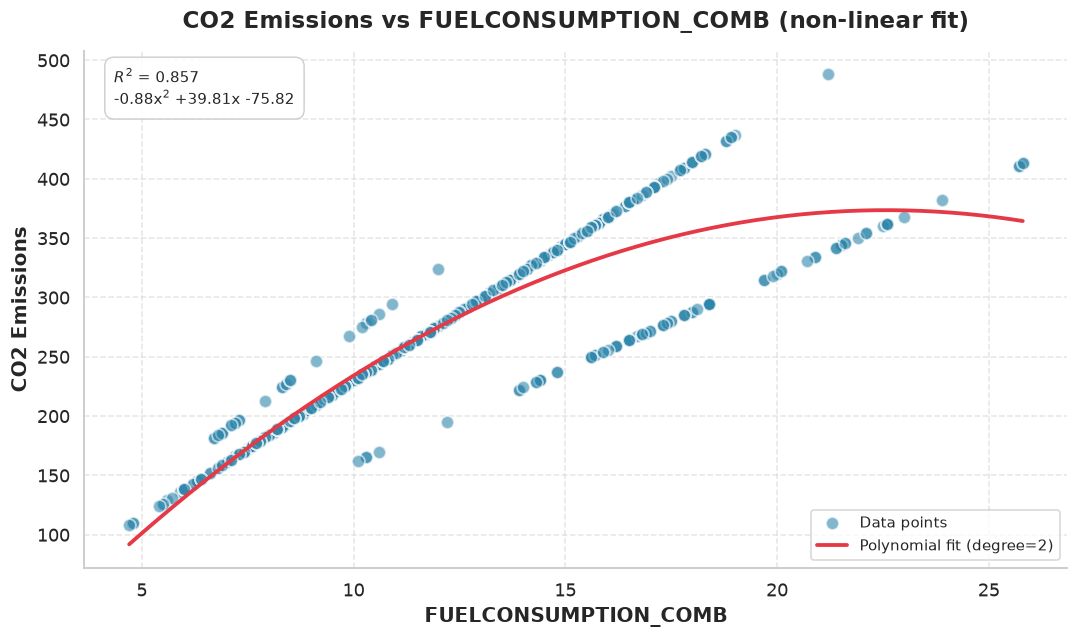

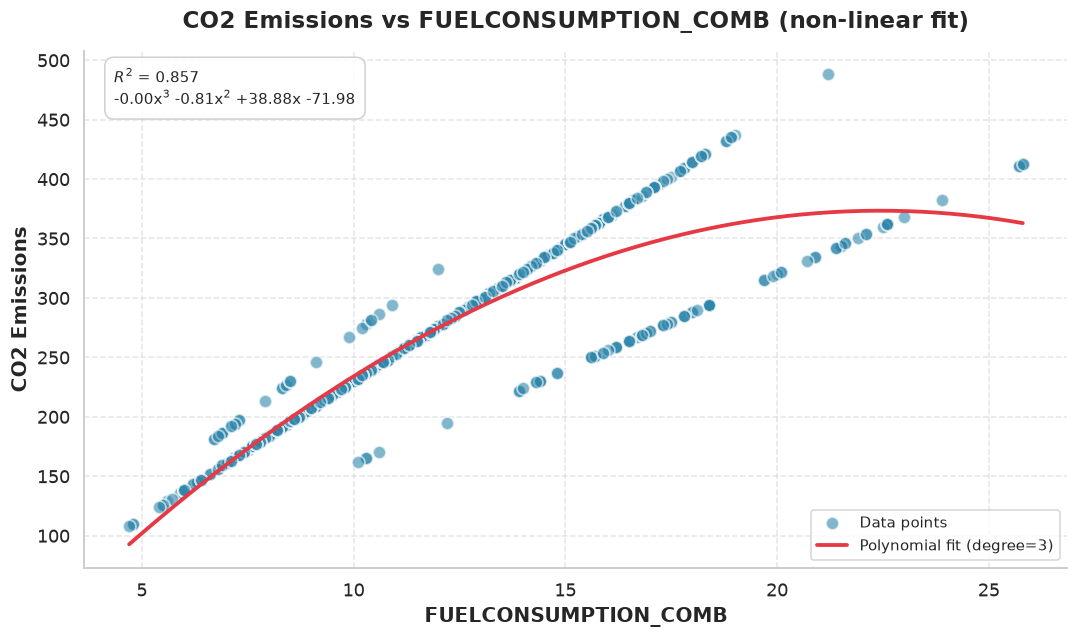

<Axes: title={'center': 'CO2 Emissions vs FUELCONSUMPTION_COMB (non-linear fit)'}, xlabel='FUELCONSUMPTION_COMB', ylabel='CO2 Emissions'>

In [75]:
# منحنی درجه ۲ (پیش‌فرض) — سهمی
plot_scatter_poly(cdf.FUELCONSUMPTION_COMB, cdf.CO2EMISSIONS,
                  xlabel="FUELCONSUMPTION_COMB", ylabel="CO2 Emissions")

# منحنی درجه ۳ — مکعبی
plot_scatter_poly(cdf.FUELCONSUMPTION_COMB, cdf.CO2EMISSIONS,
                  xlabel="FUELCONSUMPTION_COMB", ylabel="CO2 Emissions",
                  degree=3)

In [76]:
from sklearn.model_selection import train_test_split

# Input feature
X = cdf[['FUELCONSUMPTION_COMB']]
# Target
y = cdf['CO2EMISSIONS']

# Split data
x_trainـ_c, x_test_c, y_train_c, y_test_c = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [77]:
from sklearn import linear_model
regr = linear_model.LinearRegression()
regr.fit (x_trainـ_c, y_train_c)
# The coefficients
print ('Coefficients: ', regr.coef_)
print ('Intercept: ',regr.intercept_)



Coefficients:  [16.18090078]
Intercept:  69.10302617988444


In [79]:
# test rger 
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
y_pred_c = regr.predict(x_test_c)

print("Mean absolute error: %.2f" % np.mean(np.abs(y_pred_c - y_test_c)))
print("Mean squared error: %.2f" % np.mean((y_pred_c - y_test_c) ** 2))
print("R2-score: %.2f" % r2_score(y_test_c, y_pred_c))

Mean absolute error: 20.44
Mean squared error: 797.43
R2-score: 0.81


In [81]:
# test with ponlilomiality 
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import r2_score


# Polynomial regression, degree 2
model = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression()
)

# Train
model.fit(x_trainـ_c, y_train_c)


# Predict
y_pred = model.predict(x_test_c)

print("Mean absolute error: %.2f" % np.mean(np.abs(y_pred_c - y_test_c)))
print("Mean squared error: %.2f" % np.mean((y_pred_c - y_test_c) ** 2))
print("R2-score: %.2f" % r2_score(y_test_c, y_pred_c))

Mean absolute error: 20.44
Mean squared error: 797.43
R2-score: 0.81
